# Instalar el motor y abrir un artefacto confirmado

**Pregunta:** Contraste validó los modelos de tarjetas de crédito del caso C01 con las pruebas del motor `riskvalidation`. ¿Cuántas de las pruebas registradas en el motor usó esa validación, qué dijeron sus semáforos y la política instalada en tu máquina colorea las filas confirmadas igual que el artefacto?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** ninguno, este es el notebook de entrada
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este notebook puedes:

- instalar `riskvalidation` y comparar la versión que ejecutas con la versión que horneó los documentos confirmados;
- distinguir los tres tipos de documento que Contraste confirma (el índice, el manifiesto de un caso y un artefacto) y abrir uno de cada tipo;
- medir qué parte del catálogo del motor ejercitó un caso real;
- volver a colorear las filas confirmadas con la política instalada y explicar por qué un semáforo es función de la política y no solo del modelo.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt`. Instálalo una vez, en un entorno virtual, con el comando habitual:

```bash
pip install -r notebooks/requirements.txt
```

o instala solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye por ti el entorno completo, `.venv-notebooks`. Un notebook nunca instala nada por sí mismo. La celda siguiente imprime la versión de cada paquete para que la compares con las versiones fijadas.

In [1]:
# Imprime la versión de cada paquete que usa este notebook, para compararla con notebooks/requirements.txt
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import riskvalidation as rv
from riskvalidation import Light, catalogue
from riskvalidation.core.policy import default_policy, packaged_labels, packaged_policy
from riskvalidation.core.result import TestResult

for name in ("riskvalidation", "pandas", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
pandas 3.0.6
matplotlib 3.11.2


## Datos

Contraste es un banco de trabajo del validador: ajusta modelos sobre datos públicos, ejecuta en ellos las pruebas del motor y confirma el resultado como documentos JSON. Este notebook lee esos documentos y ejecuta el motor sobre lo que contienen; no ajusta ningún modelo.

- **Propietario:** este repositorio, https://github.com/fsantibanezleal/CAOS_Contraste. El proceso fuera de línea (`data-pipeline/`) y el motor escriben los documentos; el notebook los lee tal como están confirmados.
- **Los tres tipos de documento** (contrato 2): el **índice** `data/derived/manifests/index.json` enumera los casos; un **manifiesto** `data/derived/manifests/<caso>.json` describe un caso y enumera sus artefactos; un **artefacto** `data/derived/<caso>/<variante>.json` contiene los modelos, las filas de pruebas, el impacto y los hallazgos de una variante.
- **El caso que abrimos, C01:** PD de tarjetas de crédito minoristas. Sus datos reales son el archivo de tarjetas de crédito de Taiwán de la UCI (Yeh, 2009; 30.000 tarjetas; clase de licencia `mirror-allowed`, CC BY 4.0, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).
- **Archivos leídos:** `data/derived/manifests/index.json`, `data/derived/manifests/C01.json`, `data/derived/C01/holdout.json` y, para el paso de procedencia, los otros nueve documentos que enumera el manifiesto. Las rutas son relativas a la raíz del repositorio; no se necesitan datos crudos.

La celda siguiente encuentra la raíz del repositorio (el notebook está tres carpetas por debajo), define un lector y carga los tres documentos.

In [2]:
# Apunta a los documentos confirmados (el notebook está tres carpetas bajo la raíz del repositorio) y lee tres
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


index = read_json("manifests/index.json")
manifest = read_json("manifests/C01.json")
holdout = read_json("C01/holdout.json")

## Método

El método de este notebook es el vocabulario propio del motor: un registro de pruebas, una política que convierte el valor p de una prueba en un semáforo y una fila `TestResult` que guarda juntos la prueba, la política y el semáforo. Primero miramos los documentos que contienen las filas, luego contamos lo que ofrece el motor frente a lo que usó el caso y por último pedimos a la política que vuelva a colorear las filas.

### Paso 1: el índice y la pregunta del caso

El índice es la tabla de contenidos de todo lo que Contraste confirma: cuántos casos hay, cuál abre primero el sitio y la categoría de cada caso. La celda siguiente cuenta los casos por categoría e imprime la pregunta que plantea el manifiesto de C01.

In [3]:
# Cuenta los casos del índice por categoría y muestra la pregunta propia del manifiesto
by_category = Counter(case["category"]["es"] for case in index["cases"])
table = pd.Series(by_category, name="casos").sort_values(ascending=False).to_frame()
print(index["n_cases"], "casos | caso por defecto:", index["default_case"])
print(manifest["question"]["es"])
table

22 casos | caso por defecto: C01
¿Iguala una tarjeta de puntuación WoE monótona a los retadores que según la literatura pueden superarla, cuando se exige calibración, y qué dicen las pruebas de validación cuando la población cambia?


,casos
Puntuación crediticia,3
Riesgo de mercado y de contraparte,3
Balance: IRRBB y liquidez,3
Provisiones,2
Calificaciones y calibración,2
LGD y EAD,2
Capital y pruebas de tensión,2
Riesgo de modelos de ML e IA,2
Capital de cartera,1
Riesgo operacional,1


Lectura del índice: hay 22 casos en 11 categorías, y la puntuación crediticia y los dos grupos de balance y de mercado tienen tres cada uno, de modo que C01 es un caso entre muchos y los demás reutilizan el mismo motor. La pregunta de C01 son en realidad dos: si una tarjeta de puntuación monótona iguala a los retadores cuando se exige calibración, y qué dicen las pruebas de validación cuando la población cambia. La segunda es de lo que tratan las pruebas de este notebook.

### Paso 2: el manifiesto y sus artefactos

Un manifiesto enumera los artefactos de un caso con su rol: un documento `models` guarda los modelos ajustados y un documento `variant` guarda un escenario (la muestra reservada tal como se observa, una deriva, un cambio de prevalencia, ruido en las etiquetas, una muestra pequeña, un gemelo alemán). La celda siguiente enumera los diez artefactos de C01 con sus tamaños.

In [4]:
# Los artefactos que enumera el manifiesto de C01: una fila por variante, con su rol y su tamaño
listing = pd.DataFrame(manifest["artifacts"])[["role", "variant_id", "bytes"]]
listing = listing.sort_values(["role", "variant_id"]).reset_index(drop=True)
listing

,role,variant_id,bytes
0,models,models-german,48573
1,models,models-taiwan,122735
2,models,models-taiwan-small,99833
3,variant,drift-moderate,266960
4,variant,drift-severe,266255
5,variant,german-twin,250890
6,variant,holdout,293332
7,variant,label-noise,269236
8,variant,prior-shift,269422
9,variant,small-sample,234602


Lectura del listado: tres documentos `models` (los modelos de Taiwán, los modelos alemanes y un reajuste con muestra pequeña) y siete documentos `variant`, de entre 235 y 293 kilobytes cada uno. Todas las variantes comparten el mismo sobre, así que lo que aprendas con la muestra reservada abre las otras seis. El paso siguiente pregunta de dónde vienen los números: qué versión del motor calculó las pruebas de cada documento, porque un número confirmado solo es tan reciente como el motor que lo horneó.

### Paso 3: procedencia, el motor que horneó los documentos

Cada artefacto registra su `provenance`: el estado de verdad de sus datos (`real-outcomes` para el archivo de Taiwán), la semilla y la versión de `riskvalidation`. La celda siguiente lee la procedencia de los diez documentos y cuenta las versiones del motor, junto a la versión instalada en este entorno.

In [5]:
# La versión del motor que horneó cada uno de los diez documentos de C01, junto a la versión instalada aquí
documents = [read_json(item["path"]) for item in manifest["artifacts"]]
baked_with = Counter(doc["provenance"]["riskvalidation_version"] for doc in documents)
print("versiones del motor que hornearon los documentos de C01:", dict(baked_with))
print("instalada:", rv.__version__, "| documentos", sum(baked_with.values()))
print("estado de verdad de la muestra reservada:", holdout["provenance"]["truth_status"])

versiones del motor que hornearon los documentos de C01: {'1.0.1': 10}
instalada: 1.0.1 | documentos 10
estado de verdad de la muestra reservada: real-outcomes


Los diez documentos fueron horneados con `riskvalidation` 1.0.1, la versión que ejecuta este notebook, y los datos de la muestra reservada tienen desenlaces reales. Esa igualdad permite comparar más adelante el motor instalado con las filas confirmadas sin reservas; cuando un documento lleva una versión anterior, un notebook lo dice antes de comparar nada. Aquí nada reescribe un documento confirmado.

### Paso 4: ¿qué parte del catálogo usó C01?

El motor registra cada prueba con su identificador, su familia, su hipótesis nula, su fuente primaria y el tipo de decisión que respalda; `catalogue()` devuelve ese registro. Los identificadores de prueba de una fila de resultado (`pd.jeffreys`, `disc.auc`) son las mismas cadenas, de modo que el registro se puede contar frente a las filas. La celda siguiente agrupa ambos por familia y los dibuja lado a lado.

pruebas registradas: 134 | familias: 18
ejecutadas en la muestra reservada de C01: 15


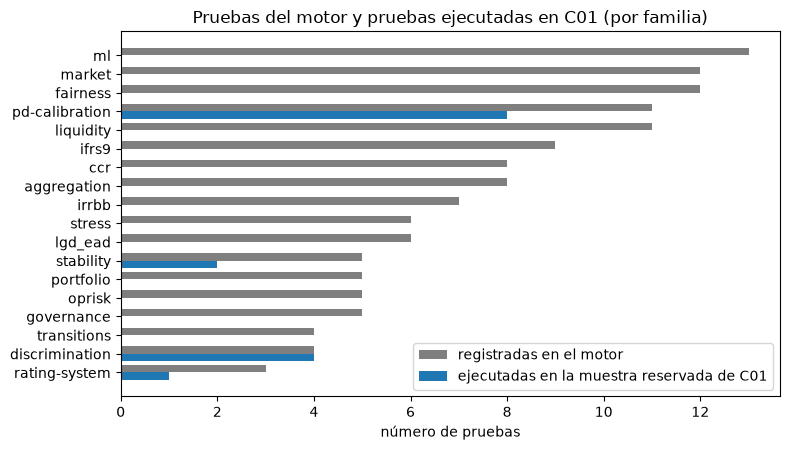

In [6]:
# Cuenta las pruebas que registra el motor por familia y cuántas ejecutó el artefacto de la muestra reservada de C01
family_of = {spec.test_id: spec.family for spec in catalogue()}
registered = Counter(family_of.values())
ran_ids = sorted({row["test_id"] for row in holdout["tests"]})
ran = Counter(family_of[test_id] for test_id in ran_ids)
print("pruebas registradas:", len(family_of), "| familias:", len(registered))
print("ejecutadas en la muestra reservada de C01:", len(ran_ids))

order = sorted(registered, key=registered.get)
positions = range(len(order))
fig, ax = plt.subplots(figsize=(8, 4.6))
up = [p + 0.2 for p in positions]
down = [p - 0.2 for p in positions]
ax.barh(up, [registered[f] for f in order], height=0.4, label="registradas en el motor", color="tab:gray")
used = [ran.get(f, 0) for f in order]
ax.barh(down, used, height=0.4, label="ejecutadas en la muestra reservada de C01", color="tab:blue")
ax.set_yticks(list(positions))
ax.set_yticklabels(order)
ax.set_xlabel("número de pruebas")
ax.set_title("Pruebas del motor y pruebas ejecutadas en C01 (por familia)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Las barras grises son lo que ofrece el motor y las barras azules lo que ejercitó la muestra reservada de C01. El caso ejecutó 15 de las 134 pruebas registradas, todas de cuatro familias: las cuatro pruebas de discriminación, ocho de las once de calibración, dos de las cinco de estabilidad y una de las tres del sistema de calificación. Las otras catorce familias (riesgo de mercado, liquidez, IFRS 9, contraparte y otras) pertenecen a otros casos y a otros temas de este conjunto de notebooks. La figura no dice cuáles son las pruebas correctas para un modelo de tarjetas de crédito; dice solo cuánto del motor necesitó este caso, para que el lector no tome las 134 como el tamaño de una validación.

### Paso 5: la política que convierte valores p en semáforos

Una prueba devuelve un estadístico y un valor p; el color viene de una política, una tabla versionada de umbrales indexada por el identificador de la prueba. `default_policy()` carga la que el motor empaqueta y `Policy.threshold(test_id)` devuelve el umbral de una prueba, o nada cuando la política no tiene ninguno. La celda siguiente enumera, para las quince pruebas que ejecutó la muestra reservada, el tipo de umbral, sus dos puntos de corte y el número de filas que esa prueba tiene en el artefacto.

In [7]:
# La política empaquetada y, para cada prueba que ejecutó la muestra reservada, su umbral (si lo hay) y sus filas
policy = default_policy()
rows_per_test = Counter(row["test_id"] for row in holdout["tests"])
cuts = []
for test_id in ran_ids:
    cut = policy.threshold(test_id)
    kind = "sin umbral" if cut is None else cut.kind
    amber = None if cut is None else cut.amber
    red = None if cut is None else cut.red
    cuts.append({"prueba": test_id, "tipo de umbral": kind, "ámbar": amber, "rojo": red,
                 "filas": rows_per_test[test_id]})
print("política:", policy.label)
pd.DataFrame(cuts).sort_values("tipo de umbral").reset_index(drop=True)

política: riskvalidation-default 2026.10.1


,prueba,tipo de umbral,ámbar,rojo,filas
0,disc.auc_vs_initial,p_value,0.05,0.01,7
1,disc.delong,p_value,0.05,0.01,6
2,pd.binomial,p_value,0.05,0.01,8
3,pd.binomial_vasicek,p_value,0.05,0.01,8
4,pd.chi2_grades,p_value,0.05,0.01,7
5,pd.hosmer_lemeshow,p_value,0.05,0.01,7
6,pd.jeffreys,p_value,0.05,0.01,70
7,pd.spiegelhalter,p_value,0.05,0.01,8
8,rating.hhi,p_value,0.05,0.01,8
9,stability.csi,p_value,0.05,0.01,20


Once pruebas llevan el mismo tipo de umbral: un valor p pasa a ámbar por debajo de 0,05 y a rojo por debajo de 0,01. Cuatro pruebas no llevan ninguno: el AUC, el estadístico de Kolmogorov-Smirnov, la puntuación de Brier y el error de calibración esperado miden separación y ajuste, y la política por defecto no fija un punto de corte para ellas. Sus filas suman 31, exactamente el número de filas `not_evaluated` que veremos más abajo, de modo que la falta de color es una decisión de la política y nunca un fallo de la prueba.

### Paso 6: las políticas que empaqueta el motor

La política por defecto es una entre varias. Un caso de Contraste puede traer su propia batería, y el motor las empaqueta todas, cada una con una etiqueta y una versión. La celda siguiente carga cada política empaquetada y cuenta sus umbrales.

In [8]:
# Las políticas que empaqueta el motor: cada etiqueta con el número de pruebas para las que tiene umbral
sizes = {label: len(packaged_policy(label).thresholds) for label in packaged_labels()}
packaged = pd.Series(sizes, name="pruebas con umbral").sort_values(ascending=False).to_frame()
print("políticas empaquetadas en el motor:", len(sizes))
packaged

políticas empaquetadas en el motor: 12


,pruebas con umbral
riskvalidation-default 2026.10.1,48
contraste-market-battery 1.0.0,12
contraste-liquidity-battery 1.0.0,11
contraste-ifrs9-battery 1.0.0,9
contraste-aggregation-battery 1.0.0,8
contraste-ccr-battery 1.0.0,8
contraste-c12 1.0.0,7
contraste-irrbb-battery 1.0.0,7
contraste-lgd-ead-battery 1.0.0,6
contraste-stress-battery 1.0.0,6


El motor empaqueta 12 políticas. La política por defecto tiene 48 umbrales, la más amplia con diferencia, y las once baterías tienen entre 5 y 12 cada una y sirven a los otros casos. La etiqueta es la identidad de una política: una fila de resultado la registra en `policy_version`, de modo que quien lee una fila confirmada siempre sabe qué tabla de umbrales la coloreó.

### Paso 7: las filas como el tipo propio del motor

Las `tests` de un artefacto son registros `TestResult` escritos como diccionarios. Reconstruirlos como objetos `TestResult` es la forma más estricta de abrir el artefacto: el constructor rechaza una fila que carece de su hipótesis nula, de su fuente o de la etiqueta de su política, o que trae un valor p fuera del intervalo unitario. La celda siguiente reconstruye las 187 filas y cuenta lo que contienen.

In [9]:
# Reconstruye cada fila confirmada como TestResult del motor, que rechaza una fila sin hipótesis nula o sin fuente
results = [TestResult(**{**row, "light": Light(row["light"])}) for row in holdout["tests"]]
with_p_value = sum(result.p_value is not None for result in results)
metric_only = sum(result.p_value is None and result.metric is not None for result in results)
print("filas reconstruidas como TestResult:", len(results))
print("con valor p:", with_p_value, "| con métrica y sin valor p:", metric_only)

filas reconstruidas como TestResult: 187
con valor p: 163 | con métrica y sin valor p: 24


Las 187 filas se reconstruyen sin error: 163 traen un valor p y 24 solo una métrica. El artefacto no contiene entonces ninguna fila mal formada, y cada fila nombra su hipótesis nula y su fuente. Las 24 filas con solo métrica son las del AUC, de Brier y del error de calibración, y las otras siete filas sin color son las de Kolmogorov-Smirnov, que tienen un valor p que la política no lee.

### Paso 8: colorear de nuevo cada fila confirmada

`Policy.classify_row(test_id, row)` toma un resultado, lee el valor p o la métrica que necesita y devuelve el semáforo según el umbral de la política. La celda siguiente lo aplica a los 187 resultados y cruza el semáforo nuevo con el que guardó el artefacto.

In [10]:
# Colorea de nuevo cada fila confirmada con la política instalada y cruza el semáforo nuevo con el horneado
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "sin evaluar"}
baked = [LIGHT[result.light.value] for result in results]
relit = [LIGHT[policy.classify_row(result.test_id, result)[0].value] for result in results]
rows_axis = pd.Series(baked, name="semáforo horneado en el artefacto")
crossing = pd.crosstab(rows_axis, pd.Series(relit, name="semáforo de la política instalada"))
print("filas coloreadas de nuevo:", len(relit))
crossing

filas coloreadas de nuevo: 187


semáforo de la política instalada,rojo,sin evaluar,verde,ámbar
semáforo horneado en el artefacto,,,,
rojo,12,0,0,0
sin evaluar,0,31,0,0
verde,0,0,136,0
ámbar,0,0,0,8


El cruce es diagonal: las 136 filas verdes siguen verdes, las 8 ámbar siguen ámbar, las 12 rojas siguen rojas y las 31 sin evaluar siguen sin evaluar, sin nada fuera de la diagonal. Un semáforo es entonces función del valor p y de la política, y el motor que instalaste reproduce la política que coloreó el artefacto. El acuerdo se cumple porque las versiones coinciden (el paso anterior); con otra política u otra versión del motor, los mismos valores p podrían colorearse distinto, que es el tema del notebook 03.

### Paso 9: ¿qué modelos dibujaron los semáforos?

El artefacto lleva las filas de ocho modelos de la escalera (una PD constante, un modelo de una variable, la tarjeta de puntuación, dos modelos logísticos penalizados, un modelo aditivo de caja de vidrio y dos modelos de gradiente). La celda siguiente conserva las filas de nivel cartera, cuenta los semáforos por modelo y los apila.

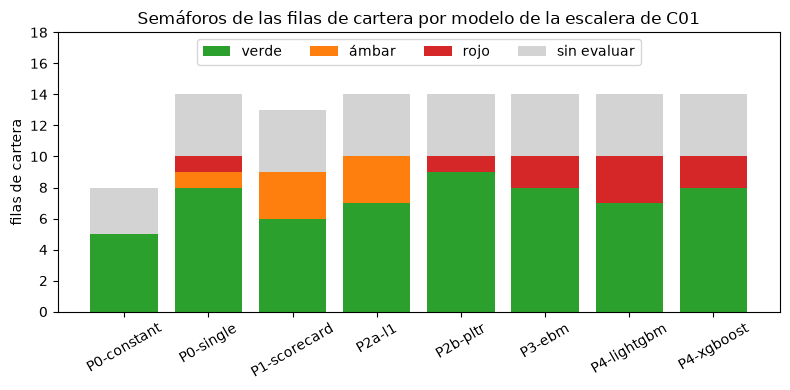

{'verde': 58, 'ámbar': 7, 'rojo': 9, 'sin evaluar': 31}


In [11]:
# Los semáforos de las filas de cartera de cada modelo de la escalera, desde el artefacto confirmado
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red", "not_evaluated": "lightgray"}
portfolio = [row for row in holdout["tests"] if row["segment"] == "portfolio" and row["model_id"]]
models = sorted({row["model_id"] for row in portfolio})
counts = Counter((row["model_id"], row["light"]) for row in portfolio)

fig, ax = plt.subplots(figsize=(8, 4))
bottom = [0] * len(models)
for light in colour:
    heights = [counts[(model, light)] for model in models]
    ax.bar(models, heights, bottom=bottom, color=colour[light], label=LIGHT[light])
    bottom = [b + h for b, h in zip(bottom, heights)]
ax.set_ylabel("filas de cartera")
ax.set_title("Semáforos de las filas de cartera por modelo de la escalera de C01")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 18)
ax.legend(ncol=4, loc="upper center")
fig.tight_layout()
plt.show()
print({LIGHT[light]: sum(v for (m, l), v in counts.items() if l == light) for light in colour})

Entre las filas de cartera hay 58 verdes, 7 ámbar, 9 rojas y 31 sin evaluar. La mayoría de los rojos está en los modelos flexibles: los modelos de gradiente y el modelo aditivo de caja de vidrio dibujan dos o tres filas rojas cada uno, la tarjeta de puntuación no tiene ninguna y tiene tres ámbar. El modelo constante, que da a cada tarjeta la misma PD, es verde en toda prueba que tiene umbral, porque su nivel es correcto en promedio; las pruebas de nivel no pueden ver que no ordena a nadie, algo que solo mostraría el AUC sin color. La figura cuenta filas y no gravedad, y no dice cuál modelo es mejor, solo dónde objetan las pruebas.

## Resultados

**Respuesta:** De las 134 pruebas registradas en el motor, la muestra reservada de C01 ejecutó 15, tomadas de cuatro de las 18 familias. Sus 187 filas de pruebas salieron 136 verdes, 8 ámbar, 12 rojas y 31 sin evaluar, y la política instalada aquí (`riskvalidation-default 2026.10.1`, motor 1.0.1) colorea las 187 filas exactamente como lo hace el artefacto.

- **Qué significa el número 15.** Una validación real usa una parte pequeña y elegida del catálogo: las pruebas que corresponden a la decisión del modelo y a sus datos. Las 134 son el tamaño de la caja de herramientas, no del trabajo.
- **Por qué 31 filas no tienen color.** Cuatro de las quince pruebas no tienen umbral en la política por defecto; las filas sin color son intencionales, y el validador lee esos números frente a un valor de referencia.
- **Lo que los semáforos no dicen.** Los rojos caen en los modelos flexibles y el modelo constante es verde, de modo que un color mide el acuerdo de una prueba con su hipótesis nula, no la calidad del modelo. Por eso el notebook 02 ejecuta tres pruebas a mano sobre un modelo y el notebook 03 cambia la política con el valor p fijo.

## Resumen

- `riskvalidation` 1.0.1 se instala con las versiones fijadas de `notebooks/requirements.txt`, y los diez documentos de C01 fueron horneados con esa misma versión.
- Contraste confirma tres tipos de documento: el índice, un manifiesto por caso y un artefacto por variante, todos con el mismo sobre.
- El motor registra 134 pruebas en 18 familias; el caso de tarjetas de crédito usó 15, y un caso siempre usa una parte elegida del catálogo.
- Un semáforo es el resultado de aplicar una política a un valor p: la `default_policy()` instalada vuelve a colorear las 187 filas confirmadas sin un solo cambio, y cuatro pruebas quedan sin color a propósito.

**Qué probar a continuación.** Abre otro artefacto de C01, por ejemplo `data/derived/C01/drift-severe.json`, y repite la figura apilada para él: los rojos deberían moverse. Después continúa con el notebook 02, en el que llamas tú mismo a una prueba sobre un corte de 50 tarjetas.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- El catálogo del motor y los contratos de documentos: `docs/contracts/engine/` y `docs/contracts/` de este repositorio.